<a href="https://colab.research.google.com/github/KesteHarshada87/Reinforcement_Learning/blob/main/Expt09(Q-Learning).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Environment: Taxi-v4
Number of states: 500
Number of actions: 6

====== PERFORMANCE COMPARISON ======
Metric                    Q-Learning         SARSA
--------------------------------------------------
Average Reward                  7.74          7.71
Success Rate (%)              100.00        100.00
Average Steps                  13.26         13.29


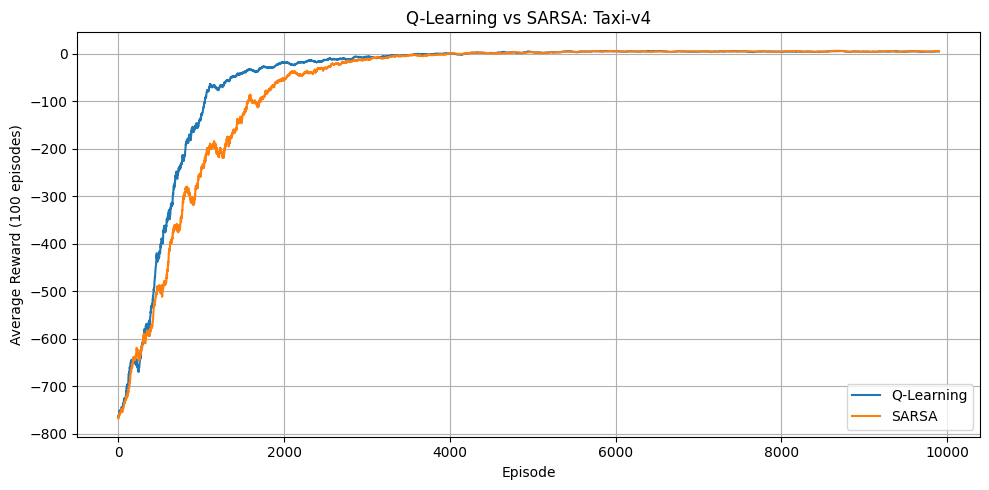

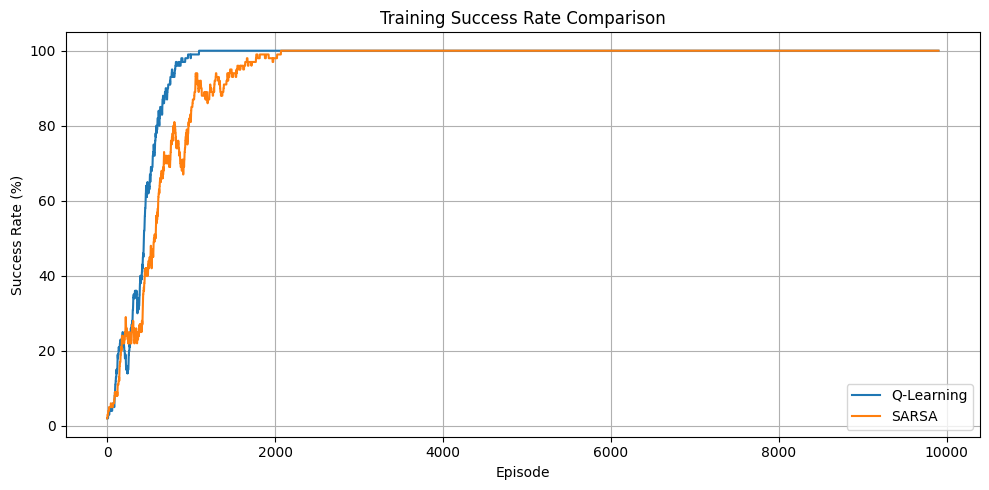


Q-Learning Q-table shape: (500, 6)
SARSA Q-table shape: (500, 6)
Experiment completed successfully.


In [2]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# Experiment 9: Q-Learning vs SARSA
# Updated environment: Taxi-v4

ENV_NAME = "Taxi-v4"

env = gym.make(ENV_NAME)

n_states = env.observation_space.n
n_actions = env.action_space.n

print("Environment:", ENV_NAME)
print("Number of states:", n_states)
print("Number of actions:", n_actions)

# Hyperparameters
alpha = 0.1
gamma = 0.99
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.9995
episodes = 10000
max_steps = 200

# Epsilon-greedy action selection
def choose_action(Q, state, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(n_actions))
    return int(np.argmax(Q[state]))


# Train Q-Learning or SARSA
def train_agent(algorithm, seed):
    Q = np.zeros((n_states, n_actions))
    rewards = []
    successes = []
    rng = np.random.default_rng(seed)
    exploration = 1.0

    for episode in range(episodes):
        state, info = env.reset(seed=seed + episode)
        action = choose_action(Q, state, exploration, rng)
        total_reward = 0
        success = False

        for step in range(max_steps):
            next_state, reward, terminated, truncated, info = (
                env.step(action)
            )
            total_reward += reward
            done = terminated or truncated

            if algorithm == "Q-Learning":
                # Use the maximum next-state Q-value
                if done:
                    target = reward
                else:
                    target = reward + gamma * np.max(Q[next_state])

                Q[state, action] += alpha * (
                    target - Q[state, action]
                )

            else:  # SARSA
                # Use the next action selected by epsilon-greedy
                if done:
                    target = reward
                else:
                    next_action = choose_action(
                        Q, next_state, exploration, rng
                    )
                    target = (
                        reward + gamma * Q[next_state, next_action]
                    )

                Q[state, action] += alpha * (
                    target - Q[state, action]
                )

            if done:
                success = terminated
                break

            if algorithm == "Q-Learning":
                next_action = choose_action(
                    Q, next_state, exploration, rng
                )

            state = next_state
            action = next_action

        rewards.append(total_reward)
        successes.append(int(success))

        exploration = max(
            epsilon_min,
            exploration * epsilon_decay
        )

    return Q, np.array(rewards), np.array(successes)


# Train both algorithms
Q_q, rewards_q, success_q = train_agent("Q-Learning", 42)
Q_s, rewards_s, success_s = train_agent("SARSA", 42)

env.close()


# Evaluate greedy policies
def evaluate_agent(Q, test_episodes=200):
    test_env = gym.make(ENV_NAME)
    total_rewards = []
    successful = 0
    steps_list = []

    for episode in range(test_episodes):
        state, info = test_env.reset(seed=20000 + episode)
        total_reward = 0

        for step in range(max_steps):
            action = int(np.argmax(Q[state]))

            state, reward, terminated, truncated, info = (
                test_env.step(action)
            )
            total_reward += reward

            if terminated or truncated:
                if terminated:
                    successful += 1
                break

        total_rewards.append(total_reward)
        steps_list.append(step + 1)

    test_env.close()

    return (
        np.mean(total_rewards),
        100 * successful / test_episodes,
        np.mean(steps_list)
    )


avg_q, rate_q, steps_q = evaluate_agent(Q_q)
avg_s, rate_s, steps_s = evaluate_agent(Q_s)

# Display comparison
print("\n====== PERFORMANCE COMPARISON ======")
print(f"{'Metric':<22}{'Q-Learning':>14}{'SARSA':>14}")
print("-" * 50)
print(f"{'Average Reward':<22}{avg_q:>14.2f}{avg_s:>14.2f}")
print(f"{'Success Rate (%)':<22}{rate_q:>14.2f}{rate_s:>14.2f}")
print(f"{'Average Steps':<22}{steps_q:>14.2f}{steps_s:>14.2f}")

# Moving average helper
def moving_average(data, window=100):
    return np.convolve(
        data,
        np.ones(window) / window,
        mode="valid"
    )


# Plot rewards
plt.figure(figsize=(10, 5))
plt.plot(
    moving_average(rewards_q),
    label="Q-Learning"
)
plt.plot(
    moving_average(rewards_s),
    label="SARSA"
)
plt.xlabel("Episode")
plt.ylabel("Average Reward (100 episodes)")
plt.title("Q-Learning vs SARSA: Taxi-v4")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot success rates
plt.figure(figsize=(10, 5))
plt.plot(
    100 * moving_average(success_q),
    label="Q-Learning"
)
plt.plot(
    100 * moving_average(success_s),
    label="SARSA"
)
plt.xlabel("Episode")
plt.ylabel("Success Rate (%)")
plt.title("Training Success Rate Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nQ-Learning Q-table shape:", Q_q.shape)
print("SARSA Q-table shape:", Q_s.shape)
print("Experiment completed successfully.")